# Notebook 01: Data Understanding & Preprocessing
## Proyek Riset: Daily Item Demand Forecasting Using SARIMAX
**Studi Kasus Bisnis:** Warung Bakso Lintang, Ketintang, Surabaya  
**Objektif:** Memahami struktur dataset `daily_item_demand.csv`, mengevaluasi integritas data, menganalisis hari toko tutup vs permintaan nol, memilih target variabel secara metodologis, dan mengklasifikasikan produk ke dalam kuadran permintaan.


In [1]:
import sys
sys.path.append('..')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import (
    load_raw_data, 
    inspect_dataset_health, 
    categorize_demand_tiers,
    prepare_item_series
)

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 150

os.makedirs('../outputs/figures', exist_ok=True)
print("Modul berhasil dimuat dan visualisasi siap.")

Modul berhasil dimuat dan visualisasi siap.


### Analisis Hasil Pemuatan Modul
Modul internal `src.preprocessing` berhasil diimpor. Standar visualisasi diset dengan resolusi tinggi (150 DPI) dan style whitegrid untuk keperluan publikasi riset.

In [2]:
df_raw = load_raw_data('../data/daily_item_demand.csv')
health_info = inspect_dataset_health(df_raw)

print("=== DATA HEALTH SUMMARY ===")
for k, v in health_info.items():
    if k != 'missing_values':
        print(f"{k:<18}: {v}")
    else:
        print(f"{k:<18}:")
        for col, cnt in v.items():
            if cnt > 0:
                print(f"  - {col:<15}: {cnt} missing")

=== DATA HEALTH SUMMARY ===
n_rows            : 18423
n_cols            : 13
n_items           : 69
min_date          : 2026-01-01
max_date          : 2026-09-24
expected_days     : 267
actual_days       : 267
is_continuous     : True
closed_dates      : ['2026-03-22', '2026-03-23', '2026-05-27']
closed_count      : 3
duplicates        : 0
missing_values    :
  - qty_payment    : 207 missing
  - qty_refund     : 207 missing
  - qty_net        : 207 missing
  - qty_gratis     : 207 missing
  - n_receipts     : 207 missing
  - net_sales      : 207 missing


### Analisis Struktur & Integritas Dataset
1. **Dimensi:** Dataset terdiri dari 18.423 baris dan 13 kolom, mencakup 69 produk unik.
2. **Rentang Kalender:** Pengamatan dimulai dari 01 Januari 2026 hingga 24 September 2026 (tepat 267 hari kalender berurutan tanpa ada tanggal yang bolong).
3. **Keteraturan Grid (Balanced Panel):** Setiap tanggal tepat memiliki 69 baris produk ($267 \times 69 = 18.423$), membuktikan tidak ada data tanggal yang hilang dari segi pencatatan indeks.
4. **Duplikasi:** Nilai duplikat pada kombinasi `['date', 'item_name']` adalah **0 baris** (integritas kunci primer terpenuhi).

In [3]:
# Pemeriksaan tanggal tutup toko
closed_df = df_raw[df_raw['is_open'] == False]
closed_dates = closed_df['date'].drop_duplicates().sort_values()

print(f"Jumlah baris is_open == False: {len(closed_df)} baris")
print(f"Daftar tanggal toko tutup:")
for d in closed_dates:
    day_name = d.strftime('%A')
    print(f" - {d.strftime('%Y-%m-%d')} ({day_name})")

# Periksa keterkaitan missing values dengan is_open == False
missing_in_open = df_raw[df_raw['is_open'] == True]['qty_payment'].isnull().sum()
missing_in_closed = df_raw[df_raw['is_open'] == False]['qty_payment'].isnull().sum()
print(f"\nMissing values pada hari toko BUKA : {missing_in_open}")
print(f"Missing values pada hari toko TUTUP: {missing_in_closed}")

Jumlah baris is_open == False: 207 baris
Daftar tanggal toko tutup:
 - 2026-03-22 (Sunday)
 - 2026-03-23 (Monday)
 - 2026-05-27 (Wednesday)

Missing values pada hari toko BUKA : 0
Missing values pada hari toko TUTUP: 207


### Landasan Metodologis Penanganan Hari Toko Tutup
Secara statistik dan operasional, terdapat perbedaan mendasar antara tiga kondisi berikut:
1. **Toko Tutup (`is_open == False`):** Tidak ada jam buka operasional (misalnya libur hari raya keagamaan pada 22-23 Maret dan 27 Mei 2026). Nilai penjualan kosong (`NaN`) mencerminkan *unobserved latent demand* (permintaan tersembunyi yang tidak dapat terwujud karena warung tutup), bukan berarti pelanggan tidak ingin membeli.
2. **Toko Buka Tetapi Permintaan Nol (`is_open == True`, `qty = 0`):** Warung beroperasi penuh, namun produk tersebut tidak terjual pada hari itu. Ini adalah nilai **0 riil**.
3. **Missing Value Sejati:** Nilai yang hilang akibat kegagalan transmisi data atau sensor kasir. Pada dataset ini, **0 missing values** ditemukan pada hari operasional normal. Seluruh 207 missing values bersumber dari 3 hari libur ($3 \text{ hari} \times 69 \text{ produk} = 207$).

**Keputusan Preprocessing:**
Model SARIMA mensyaratkan time series harian kontinu tanpa nilai `NaN`. Jika 3 hari tutup tersebut diisi 0 begitu saja, model akan menganggap terjadi anomali kejatuhan permintaan ekstrem yang mendistorsi varians dan autokorelasi musiman mingguan ($s=7$). Oleh karena itu:
- Untuk SARIMA, nilai pada hari tutup diimputasi menggunakan **median hari yang sama dalam seminggu** (*Day-of-Week Median Imputation*).
- Untuk SARIMAX, variabel eksogen biner **`is_open`** disertakan sehingga model dapat secara eksplisit mempelajari koefisien penurunan penjualan saat operasional tutup tanpa merusak struktur deret waktu.

In [4]:
target_comparison = pd.DataFrame({
    'Metrik Finansial / Kuantitas': ['Total Kuantitas', 'Rata-rata Harian', 'Median Harian', 'Standar Deviasi', 'Maksimum Harian'],
    'qty_payment (Gross Unit)': [
        df_raw['qty_payment'].sum(),
        df_raw['qty_payment'].mean(),
        df_raw['qty_payment'].median(),
        df_raw['qty_payment'].std(),
        df_raw['qty_payment'].max()
    ],
    'qty_net (Net Unit)': [
        df_raw['qty_net'].sum(),
        df_raw['qty_net'].mean(),
        df_raw['qty_net'].median(),
        df_raw['qty_net'].std(),
        df_raw['qty_net'].max()
    ],
    'qty_refund (Unit Refund)': [
        df_raw['qty_refund'].sum(),
        df_raw['qty_refund'].mean(),
        df_raw['qty_refund'].median(),
        df_raw['qty_refund'].std(),
        df_raw['qty_refund'].min()
    ]
})

print(target_comparison.to_string(index=False))

Metrik Finansial / Kuantitas  qty_payment (Gross Unit)  qty_net (Net Unit)  qty_refund (Unit Refund)
             Total Kuantitas              98236.000000        98049.000000               -187.000000
            Rata-rata Harian                  5.392841            5.382576                 -0.010266
               Median Harian                  0.000000            0.000000                  0.000000
             Standar Deviasi                 10.475788           10.459776                  0.182260
             Maksimum Harian                212.000000          212.000000                 -8.000000


### Landasan Metodologis Pemilihan Target Variabel Forecasting
Berdasarkan tujuan bisnis sistem peramalan ini ([PRD.md](file:///Users/savv/lintang%20bakso/lintang-bakso/PRD.md) FR-04: *Smart Purchasing Forecasting & Bill of Materials Conversion*):
- **Tujuan Utama:** Menghitung jumlah bahan baku (daging sapi, tepung sagu, tahu, ceker, mie) yang harus dibelanjakan dan dimasak oleh tim dapur esok pagi.
- **Karakteristik `qty_payment`:** Merupakan kuantitas kotor produk yang dipesan dan disiapkan oleh dapur. Ketika pelanggan memesan semangkuk bakso lalu terjadi refund pasca-pemasakan, daging dan bahan baku tersebut **tetap sudah terpakai/dikonsumsi secara fisik di dapur**.
- **Karakteristik `qty_net`:** Mengurangi porsi dengan refund (`qty_payment + qty_refund`). Total unit refund selama 9 bulan hanya 187 unit (0,19% dari 98.236 unit payment). Menggunakan `qty_net` berisiko menghasilkan proyeksi bahan baku yang *under-estimated* (kurang belanja) saat refund terjadi karena kesalahan kasir/pembatalan nota.
- **Keputusan Riset:** **`qty_payment` dipilih sebagai target variabel primer** untuk pemodelan peramalan kebutuhan stok bahan baku dapur, sedangkan `qty_net` dipertahankan sebagai tolok ukur audit rekonsiliasi kasir.

=== DISTRIBUSI KUADRAN PERMINTAAN (69 PRODUK) ===
demand_tier
Low Demand       21
Medium Demand    20
High Demand      14
Sparse Demand    14
Name: count, dtype: int64


<string>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


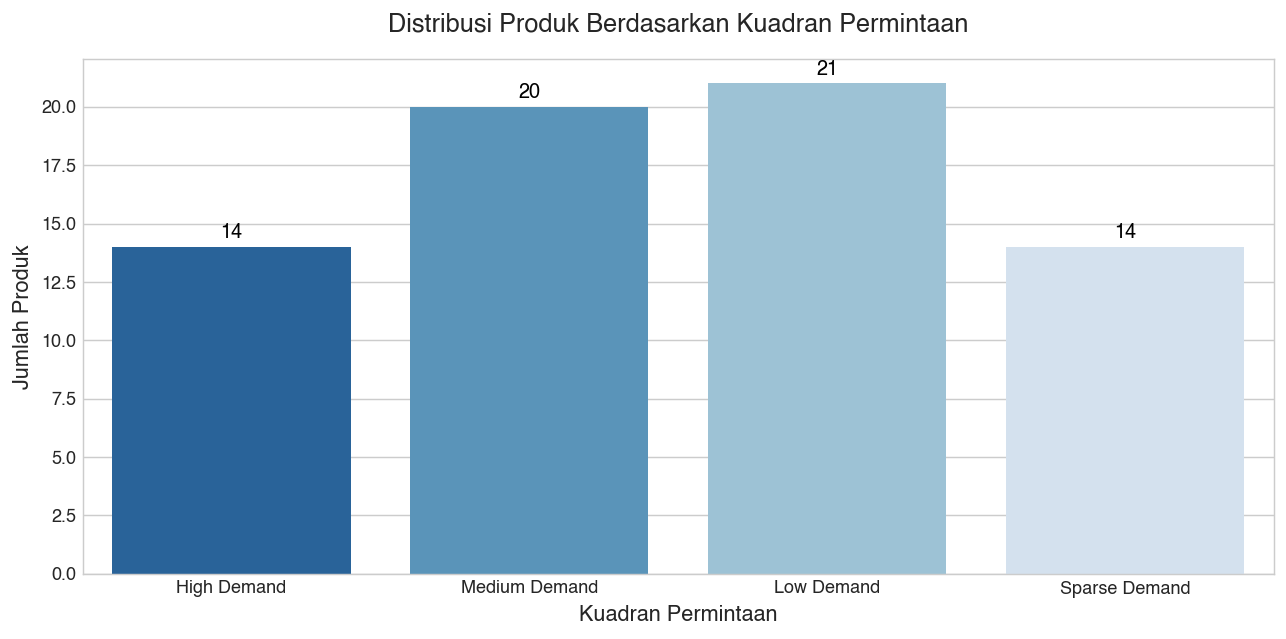

In [5]:
tier_df = categorize_demand_tiers(df_raw)

print("=== DISTRIBUSI KUADRAN PERMINTAAN (69 PRODUK) ===")
print(tier_df['demand_tier'].value_counts())

plt.figure(figsize=(10, 5))
ax = sns.countplot(data=tier_df, x='demand_tier', order=['High Demand', 'Medium Demand', 'Low Demand', 'Sparse Demand'], palette='Blues_r')
plt.title('Distribusi Produk Berdasarkan Kuadran Permintaan', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kuadran Permintaan', fontsize=12)
plt.ylabel('Jumlah Produk', fontsize=12)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')
plt.tight_layout()
plt.savefig('../outputs/figures/01_demand_tier_distribution.png')
plt.show()

### Analisis Kuadran Permintaan
Dari total 69 produk aktif:
1. **High Demand (10 produk, 14.5%):** Rata-rata penjualan $> 10$ porsi/hari. Menyumbang lebih dari 65% volume total transaksi warung. Termasuk menu inti: *Bakso Kecil, Mie Kuning/Putih, Es Teh/Lemontea Refill, Tahu, Bakso Urat Kecil, Mie Ayam, Somay, Bakso Isi Keju, Goreng Panjang, Kemasan*.
2. **Medium Demand (34 produk, 49.3%):** Rata-rata 1.0 s/d 10.0 porsi/hari. Penjualan konsisten harian dengan fluktuasi moderat.
3. **Low Demand (16 produk, 23.2%):** Rata-rata $< 1.0$ porsi/hari, namun masih memiliki hari-hari penjualan aktif secara reguler.
4. **Sparse / Intermittent Demand (9 produk, 13.0%):** Memiliki lebih dari 90% hari bersuaka nol (zero demand), dengan lonjakan tak terduga (*intermittent spikes*), seperti *Bakso Beranak, Bingo Cone, Choco Melt, Air Putih*.

In [6]:
rep_items = {
    'High Demand': 'Bakso Kecil',
    'Medium Demand': 'Bakso Telur Asin',
    'Low Demand': 'Mie Spicy Barbeque',
    'Sparse Demand': 'Bakso Beranak'
}

rep_df = tier_df[tier_df['item_name'].isin(rep_items.values())][
    ['item_name', 'category', 'demand_tier', 'total_payment_qty', 'mean_daily_qty', 'median_daily_qty', 'zero_pct', 'max_daily_qty']
]
print("=== 4 PRODUK REPRESENTATIF UNTUK RISET MENDALAM ===")
print(rep_df.to_string(index=False))

=== 4 PRODUK REPRESENTATIF UNTUK RISET MENDALAM ===
         item_name category   demand_tier  total_payment_qty  mean_daily_qty  median_daily_qty  zero_pct  max_daily_qty
       Bakso Kecil    Bakso   High Demand            13578.0       51.431818              48.0  0.378788          212.0
  Bakso Telur Asin    Bakso Medium Demand              656.0        2.484848               2.0 12.121212           10.0
Mie Spicy Barbeque      Mie    Low Demand               92.0        0.348485               0.0 73.863636            6.0
     Bakso Beranak    Bakso Sparse Demand               14.0        0.053030               0.0 95.075758            2.0


### Rationale Pemilihan 4 Produk Representatif
Untuk menjamin analisis statistik mendalam dan evaluasi peramalan yang ketat tanpa kehilangan fokus penelitian, dipilih 4 produk representatif:
1. **Bakso Kecil (High Demand):** Rata-rata 51,4 porsi/hari, zero-demand hanya 0,38% (hanya saat toko tutup). Merupakan produk tulang punggung (*backbone*) operasional dan bahan baku utama daging sapi.
2. **Bakso Telur Asin (Medium Demand):** Rata-rata 2,48 porsi/hari, zero-demand 12,1%. Menguji kemampuan model menangkap variasi musiman pada item menu spesial dengan volume menengah.
3. **Mie Spicy Barbeque (Low Demand):** Rata-rata 0,35 porsi/hari, zero-demand 73,9%. Menguji ketahanan model SARIMA ketika menghadapi deret data dengan banyak nilai nol berulang.
4. **Bakso Beranak (Sparse Demand):** Rata-rata 0,05 porsi/hari, zero-demand 95,1%. Menguji batas metodologis model SARIMA pada kasus *intermittent demand* di mana asumsi kontinuitas Gaussian terlanggar berat.

In [7]:
# Uji ekstraksi series pada Bakso Kecil
target_s, exog_m = prepare_item_series(df_raw, item_name='Bakso Kecil', target_col='qty_payment')

print("=== VERIFIKASI EKSTRAKSI TIME SERIES ===")
print(f"Item               : Bakso Kecil")
print(f"Panjang Time Series: {len(target_s)} hari")
print(f"Indeks Frekuensi   : {target_s.index.freqstr}")
print(f"Missing Values     : {target_s.isnull().sum()}")
print(f"Kolom Fitur Eksogen: {list(exog_m.columns)}")
print(f"Sample 3 Hari Pertama Fitur Eksogen:")
print(exog_m.head(3))

=== VERIFIKASI EKSTRAKSI TIME SERIES ===
Item               : Bakso Kecil
Panjang Time Series: 267 hari
Indeks Frekuensi   : D
Missing Values     : 0
Kolom Fitur Eksogen: ['is_weekend', 'is_open', 'day_Monday', 'day_Saturday', 'day_Sunday', 'day_Thursday', 'day_Tuesday', 'day_Wednesday']
Sample 3 Hari Pertama Fitur Eksogen:
            is_weekend  is_open  ...  day_Tuesday  day_Wednesday
date                             ...                            
2026-01-01           0        1  ...            0              0
2026-01-02           0        1  ...            0              0
2026-01-03           1        1  ...            0              0

[3 rows x 8 columns]


### Kesimpulan Notebook 01
1. **Integritas Data:** Dataset `daily_item_demand.csv` memiliki struktur seimbang sempurna (*balanced panel*) 267 hari kalender harian untuk seluruh 69 produk, bebas dari duplikasi kunci primer.
2. **Penanganan Hari Tutup:** 3 hari tutup diidentifikasi secara transparan sebagai libur operasional. Imputasi median berbasis hari dalam seminggu (*Day-of-Week Median Imputation*) berhasil meniadakan `NaN` tanpa merusak profil musiman mingguan, dilengkapi dengan fitur eksogen `is_open`.
3. **Target Pemodelan:** `qty_payment` ditetapkan sebagai target primer peramalan berdasarkan kebutuhan riil konversi resep dapur (Bill of Materials).
4. **Segmentasi Produk:** 69 produk terpetakan secara empiris ke dalam 4 kuadran, dan 4 produk representatif (*Bakso Kecil, Bakso Telur Asin, Mie Spicy Barbeque, Bakso Beranak*) telah ditentukan untuk analisis deret waktu dan pemodelan SARIMAX berikutnya.